# Hindcast skill vs. number of start years

How does skill, and its uncertainty, depend on the number of start years N? Each experiment's ensemble mean is scored on random subsets of N of its May starts. Lines are the median over subsets, bands the 5–95 % range; the dashed curve is the smallest ACC significant at `SIG_LEVEL` for N independent years. Two experiments whose bands overlap at a given N cannot be distinguished with N start years. Subsets near the full record overlap heavily, so their spread understates the uncertainty of a truly independent sample of that size.

**Definitions** (identical to `stats.compute_skill_seasonal`, verified in `tests/test_sample_size_skill.py`):
ACC is the Pearson correlation of the ensemble-mean and observed anomalies over the selected years;
nRMSE is their RMSE divided by the observed standard deviation; with `DETREND = True` a linear trend
in initialization year is removed from both first. Area means average the score maps (cos-latitude
weights) over each region. Inputs are only read (test root first, then production): run 1a_atm (TS,
TREFHT, PRECT, PSL), 3a and 1a_lnd first for any field you want here. Shared loading, region means and
plotting live in `workflows/diagnostics/sample_size.py`.

Experiments: E3SMv3-FOSIRL and E3SMv3-Reanalysis, the two hindcasts with complete long records (May
starts 1980–2018), so the results rest on the full record.

In [6]:
# Test-run output roots (set before importing esp_lab so every module sees them).
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd

from esp_lab import env_paths
from esp_lab import sample_size_skill as sss
from workflows.diagnostics import sample_size as ss

In [7]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INIT_MONTH = 5
RANDOM_SEED = 42
N_DRAWS = 100               # random subsets per sample size
RUN_GROUPS = ["atm", "sst", "lnd"]   # drop groups to shorten a run
QUICK = False               # True: 40 draws and the first field of each group only

# The two experiments with complete long hindcast records (May starts 1980-2018), so every
# curve rests on the full record. "years" is the start-year span a cache must lie within.
EXPERIMENTS = {
    "E3SM-FOSIRL":     dict(tag="JRA55_FOSIRL", label="E3SMv3-FOSIRL",     color="black",    years=(1980, 2018)),
    "E3SM-Reanalysis": dict(tag="Reanalysis",   label="E3SMv3-Reanalysis", color="tab:blue", years=(1980, 2018)),
}
MIN_YEARS = 6               # experiments with fewer observed start years are skipped for that field

ATM_FIELDS = ["TS", "TREFHT", "PRECT", "PSL"]
SST_INDICES = ["Nino3.4", "Nino3", "Nino4", "IOD", "TNA", "AtlNino"]
LAND_FIELDS = ["H2OSNO", "H2OSOI", "TWS"]

# Regions for gridded fields: (lat0, lat1, surface); land fields use finite land points.
ATM_REGIONS = {
    "Global 60S-80N": (-60, 80, "all"), "Land 60S-80N": (-60, 80, "land"),
    "Ocean 60S-60N": (-60, 60, "ocean"), "Tropics 20S-20N": (-20, 20, "all"),
}
LAND_REGIONS = {"Land 60S-80N": (-60, 80, "all"), "NH 30N-80N": (30, 80, "all")}

# Figures: one row per field/index, one column per lead (positions in each group's lead axis).
PLOT_REGION = {"atm": "Global 60S-80N", "lnd": "Land 60S-80N", "sst": "index"}
PLOT_LEADS = {"atm": [0, 2, 4], "sst": [0, 2, 4], "lnd": [0, 1, 2]}
DETREND = True
N_GRID = [5, 6, 7, 8, 10, 12, 14, 16, 20, 24, 28, 32, 39]   # start years (values above a record are dropped)
SIG_LEVEL = 0.1             # ACC significance threshold drawn on the figures
SUMMARY_N = [10, 16]        # record lengths summarized against the full record (e.g. the 4DEnVar runs)
# ===== END CONFIGURATION BLOCK =====

## Inputs

For every experiment and field the longest cached record inside its span is used; only start years with observations are kept. The table lists what was found.

In [8]:
if QUICK:
    N_DRAWS = 40
    ATM_FIELDS, SST_INDICES, LAND_FIELDS = ATM_FIELDS[:1], SST_INDICES[:1], LAND_FIELDS[:1]

S2D_DIAG_ROOT = env_paths.s2d_diag_root()
READ_ROOTS = list(dict.fromkeys([S2D_DIAG_ROOT, Path("/global/cfs/cdirs/e3sm/S2S2D/s2d_diag")]))
FIGURE_DIR = env_paths.figure_root() / "sample_size"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = S2D_DIAG_ROOT / "multimodel" / "sample_size"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)

GROUP_FIELDS = {"atm": ATM_FIELDS, "sst": SST_INDICES, "lnd": LAND_FIELDS}
DATA, inventory = ss.load_inputs(
    {group: GROUP_FIELDS[group] for group in RUN_GROUPS}, EXPERIMENTS,
    read_roots=READ_ROOTS, init_month=INIT_MONTH, min_years=MIN_YEARS,
)
REDUCE = ss.region_reducers(READ_ROOTS, ATM_REGIONS, LAND_REGIONS)
PLOT = dict(experiments=EXPERIMENTS, plot_region=PLOT_REGION, plot_leads=PLOT_LEADS)
print(f"Read roots: {[str(r) for r in READ_ROOTS]}\nFigures: {FIGURE_DIR}\nTables: {TABLE_DIR}")
inventory.drop(columns="file", errors="ignore").fillna("")

Read roots: ['/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test', '/global/cfs/cdirs/e3sm/S2S2D/s2d_diag']
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size
Tables: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/sample_size


,group,field,experiment,status,years,n_years,members
0,atm,TS,E3SM-FOSIRL,used,1980-2017,38,10
1,atm,TS,E3SM-Reanalysis,used,1980-2017,38,10
2,atm,TREFHT,E3SM-FOSIRL,used,1980-2017,38,10
3,atm,TREFHT,E3SM-Reanalysis,used,1980-2017,38,10
4,atm,PRECT,E3SM-FOSIRL,used,1980-2015,36,10
5,atm,PRECT,E3SM-Reanalysis,used,1980-2015,36,10
6,atm,PSL,E3SM-FOSIRL,used,1980-2011,32,10
7,atm,PSL,E3SM-Reanalysis,used,1980-2011,32,10
8,sst,Nino3.4,E3SM-FOSIRL,used,1980-2018,39,10
9,sst,Nino3.4,E3SM-Reanalysis,used,1980-2018,39,10


## Skill vs. number of start years

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/n

done: atm TS


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/n

done: atm TREFHT


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/n

done: atm PRECT


... (14 outputs left out)

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4671: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4671: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/global/homes/z/zhan391/.conda/envs/e3sm_analysi

done: lnd H2OSNO


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/n

done: lnd H2OSOI
done: lnd TWS
Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_acc_atm.png


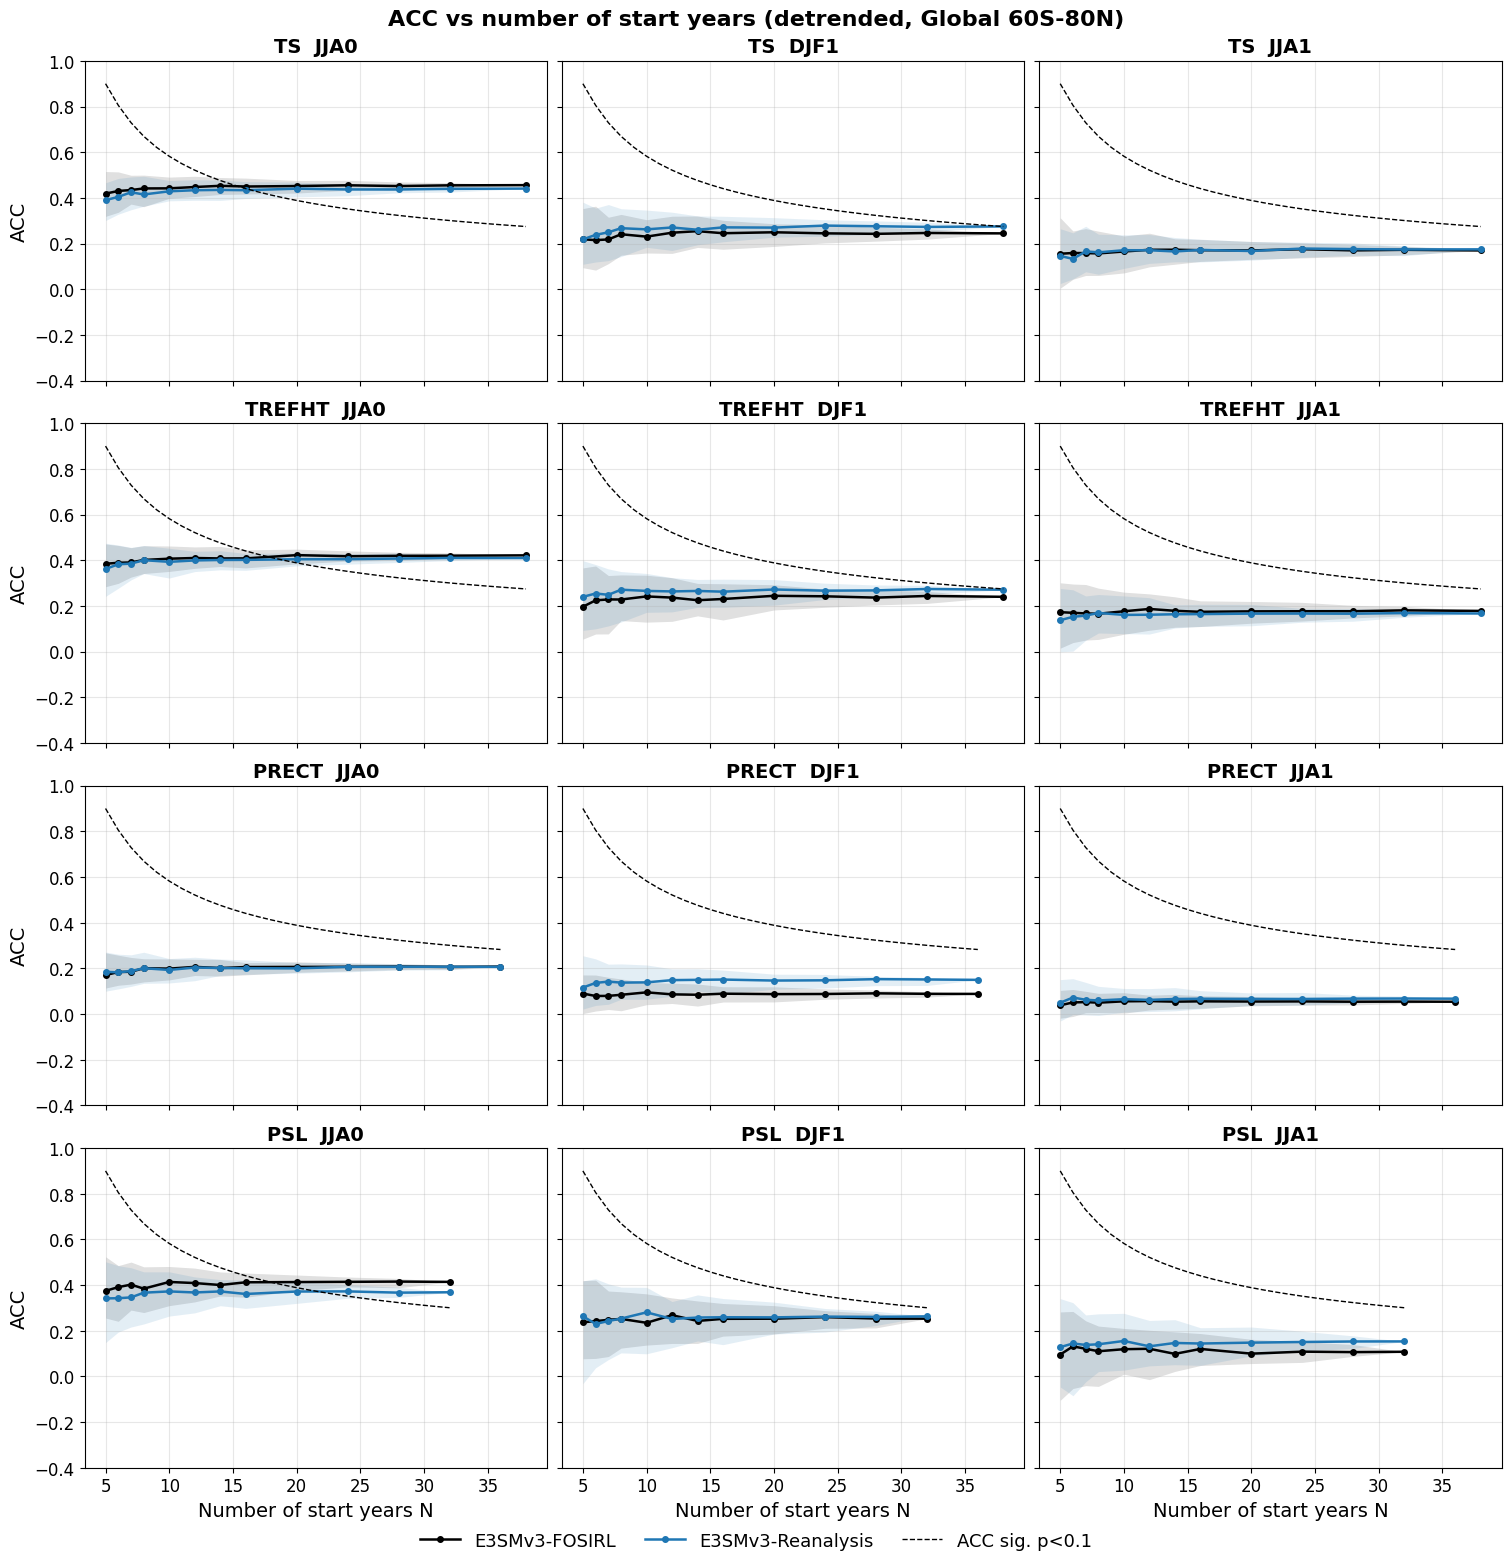

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_nrmse_atm.png


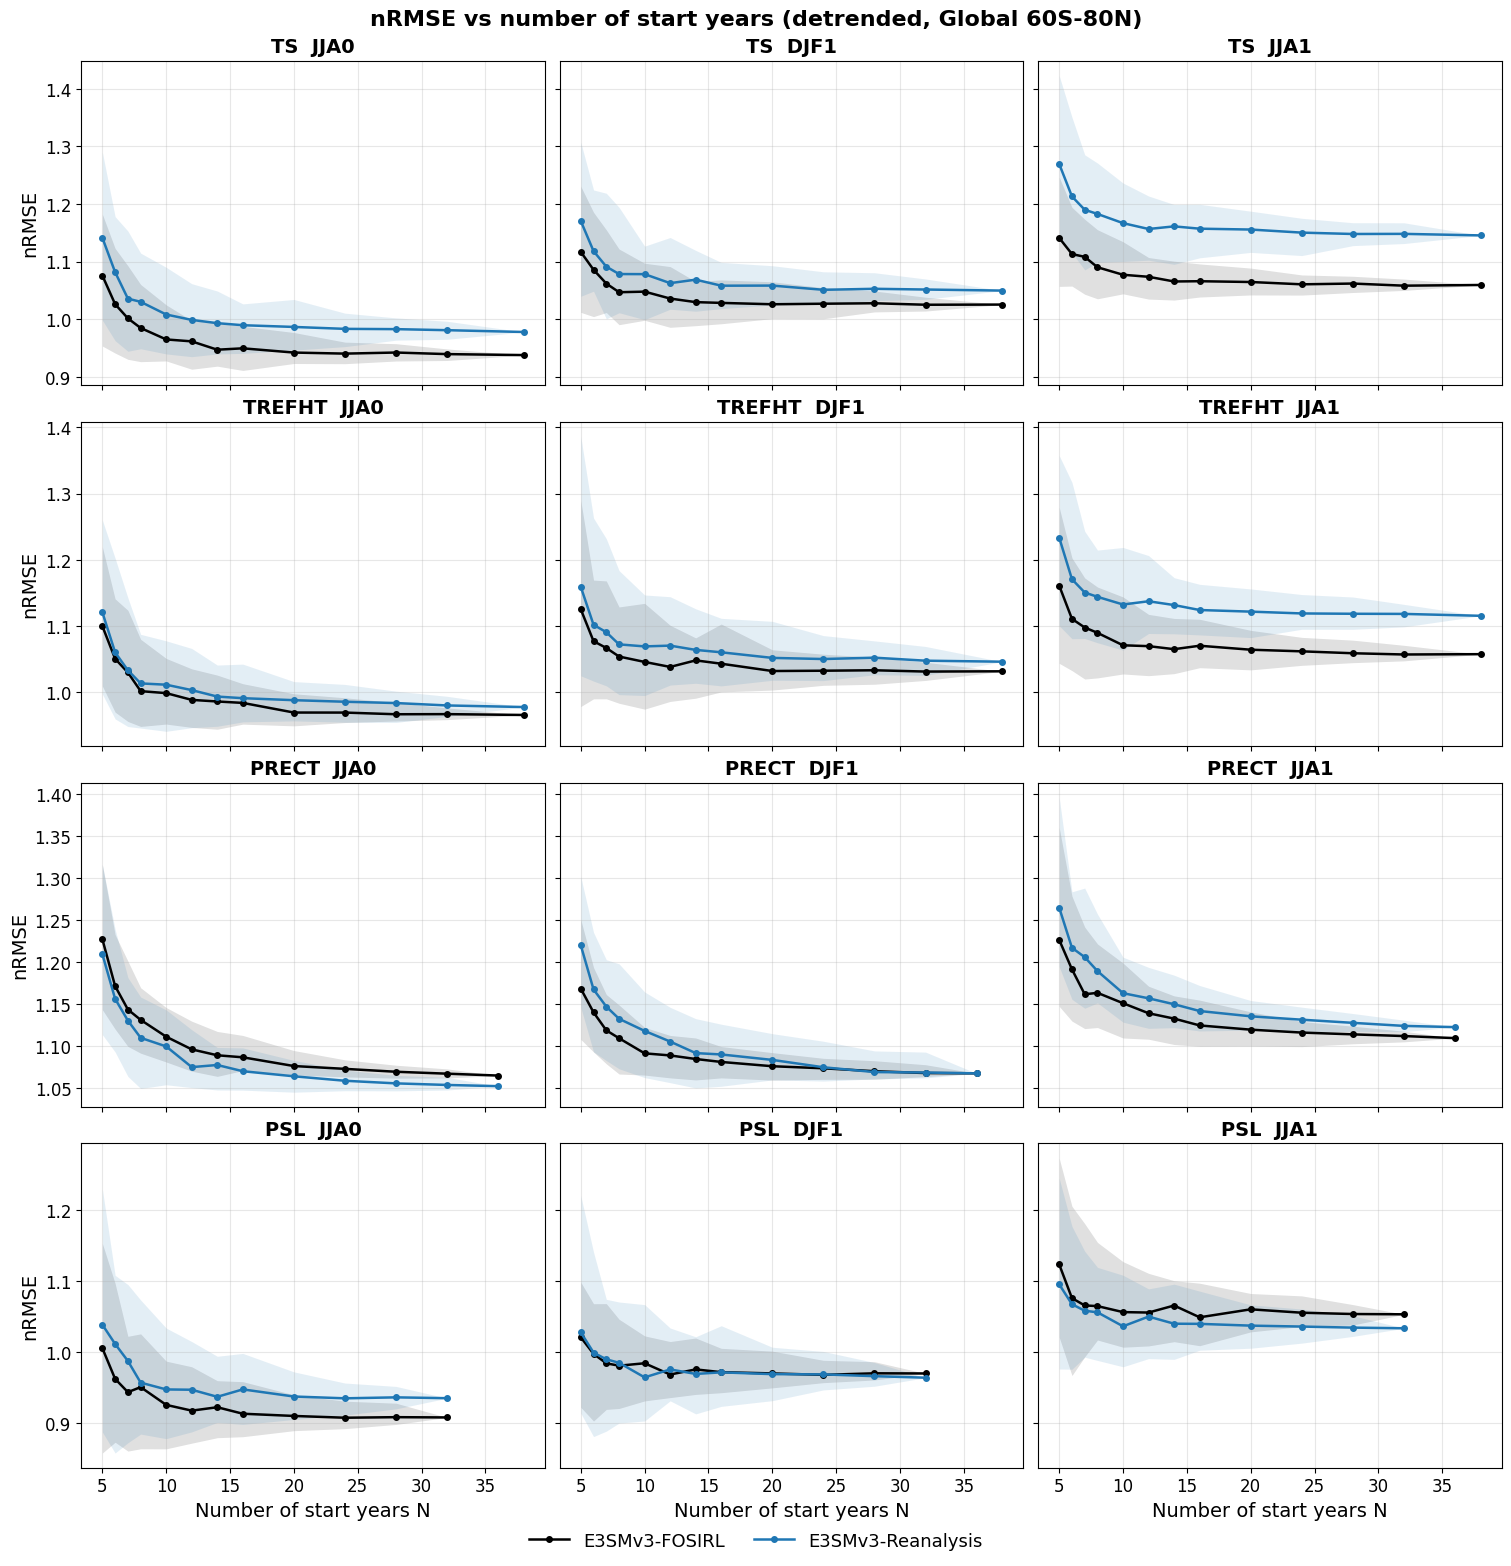

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_acc_sst.png


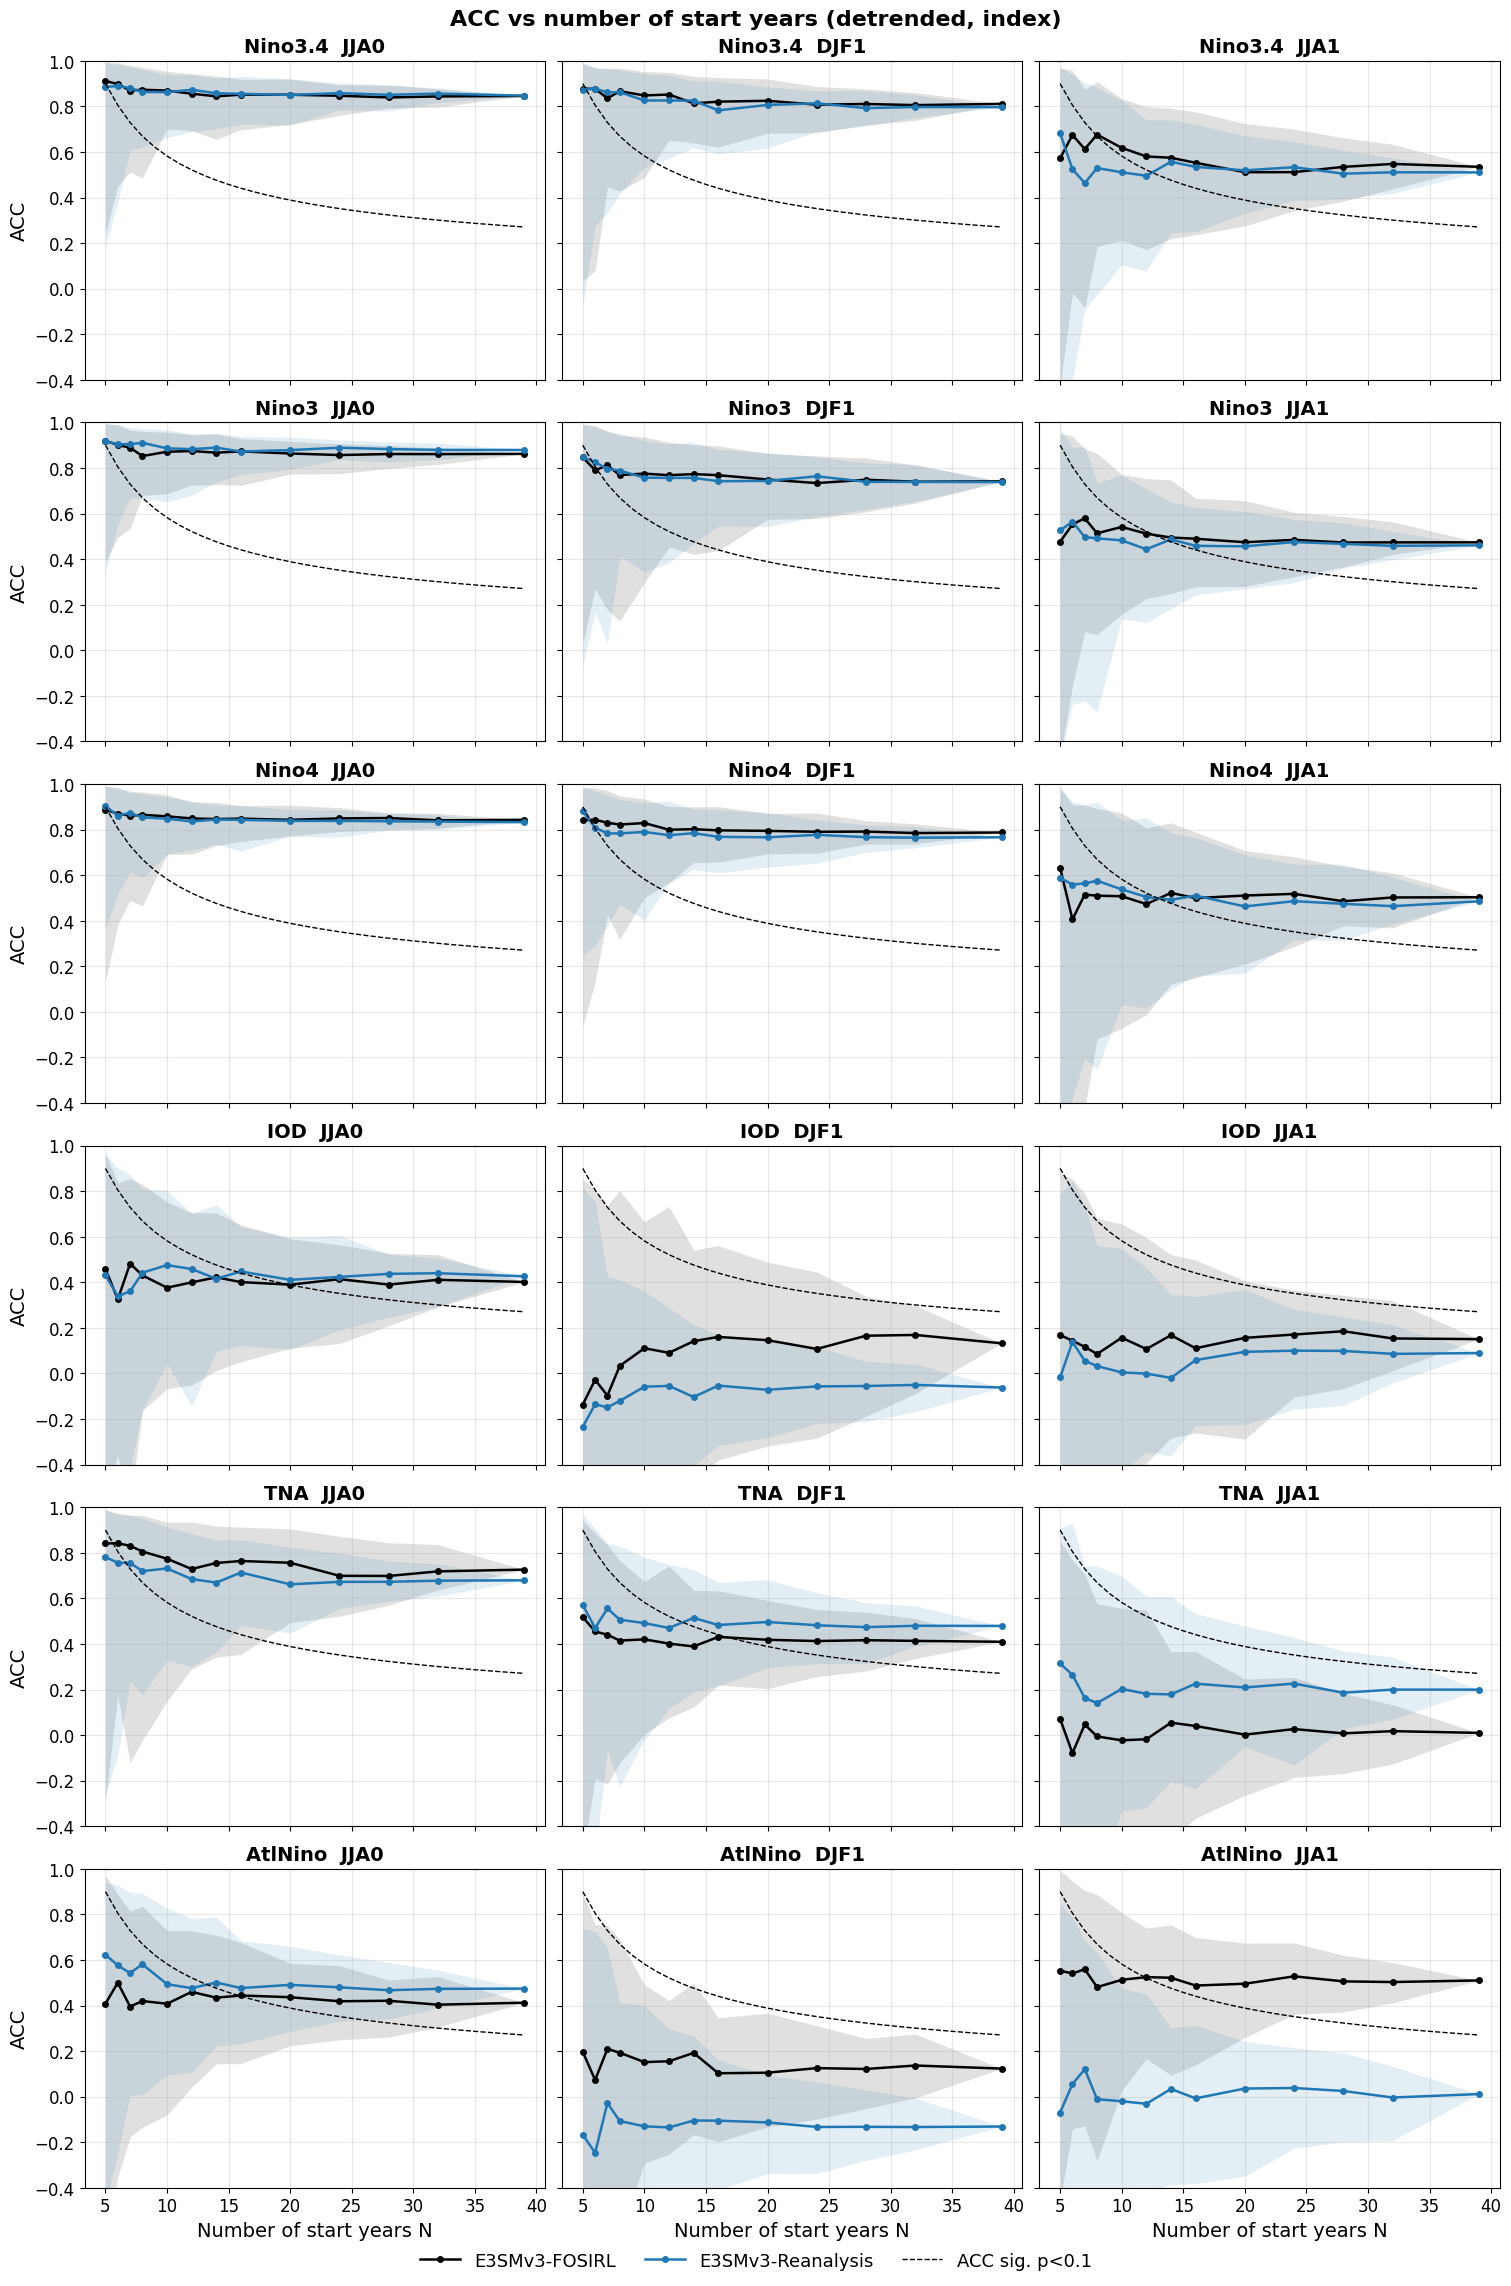

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_nrmse_sst.png


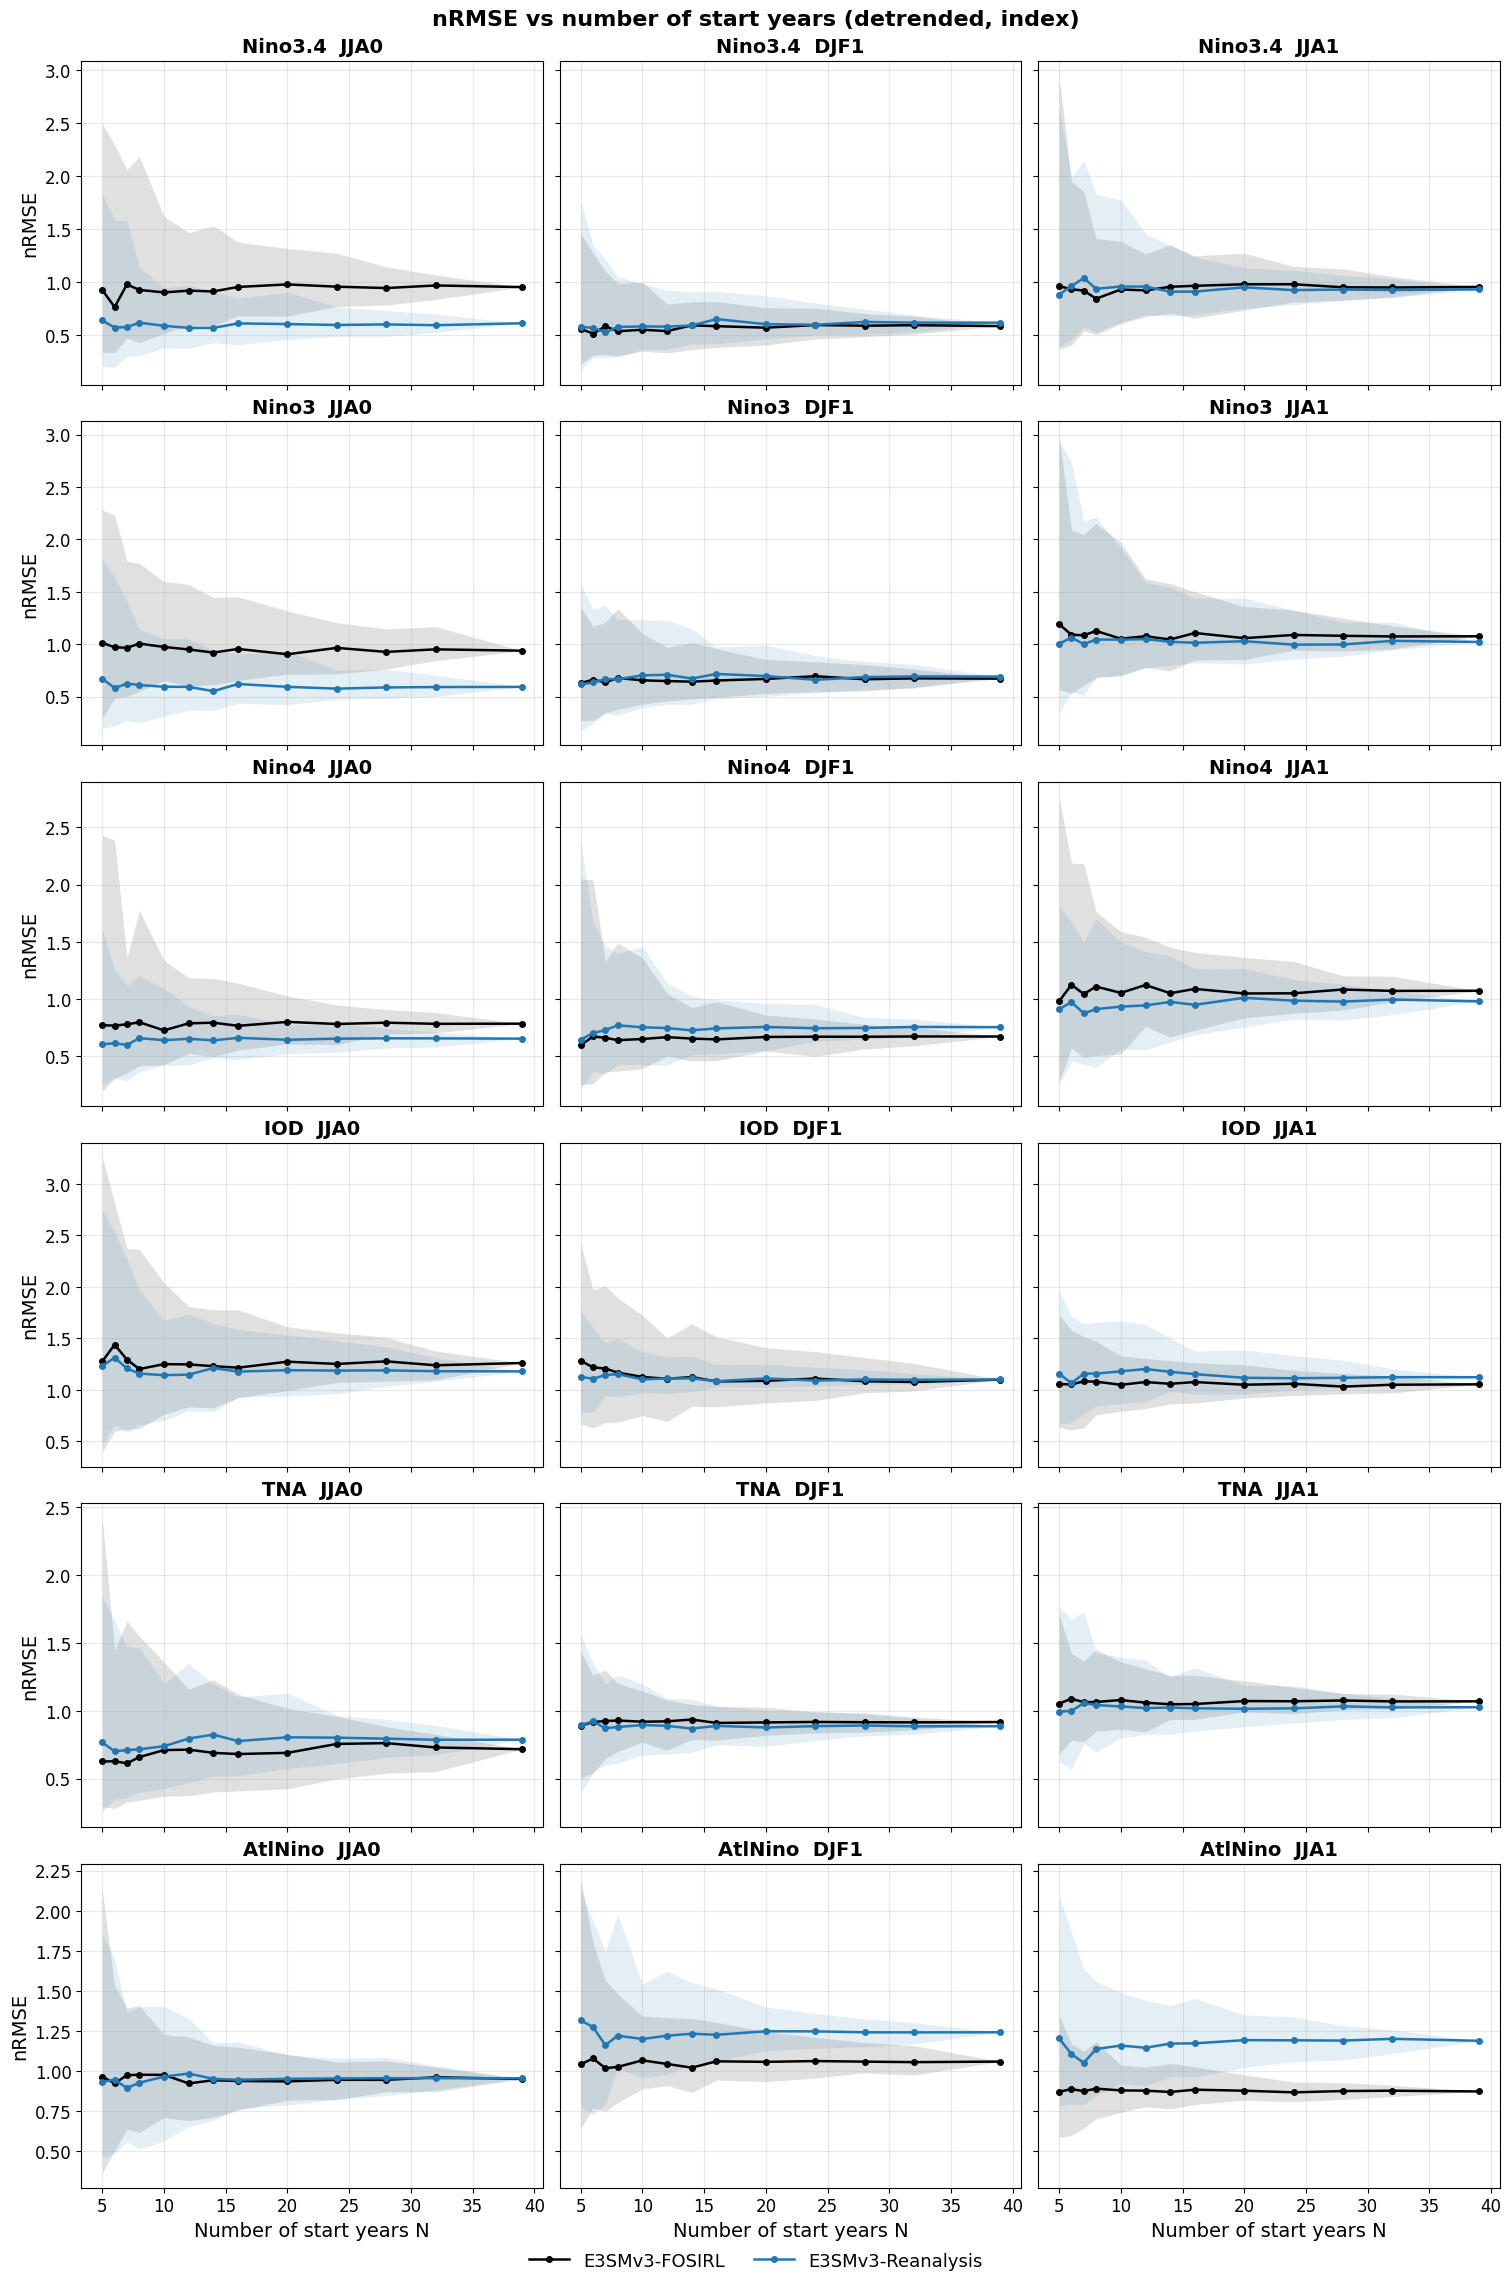

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_acc_lnd.png


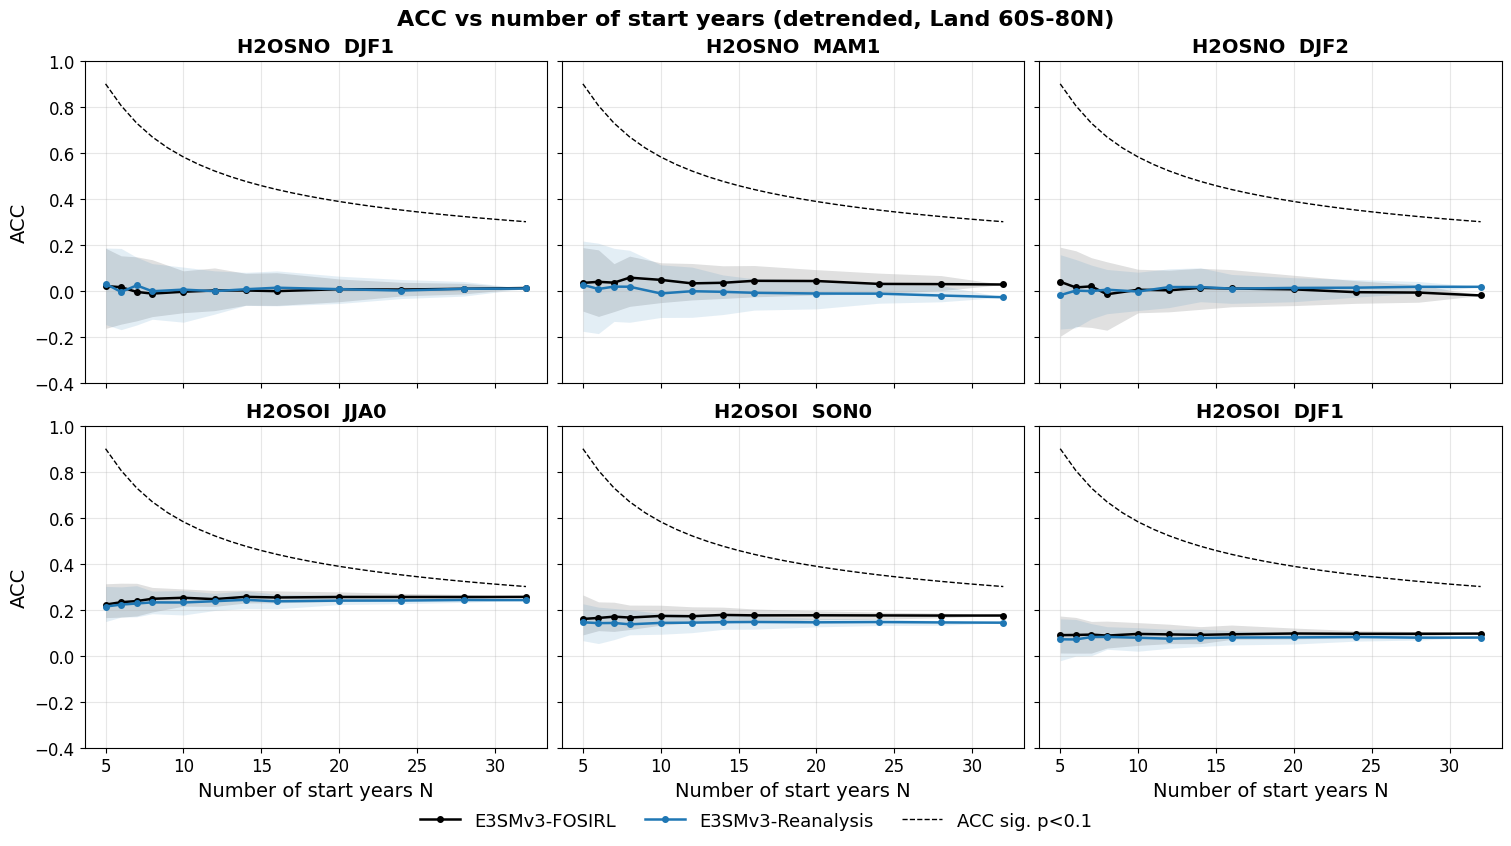

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_nrmse_lnd.png


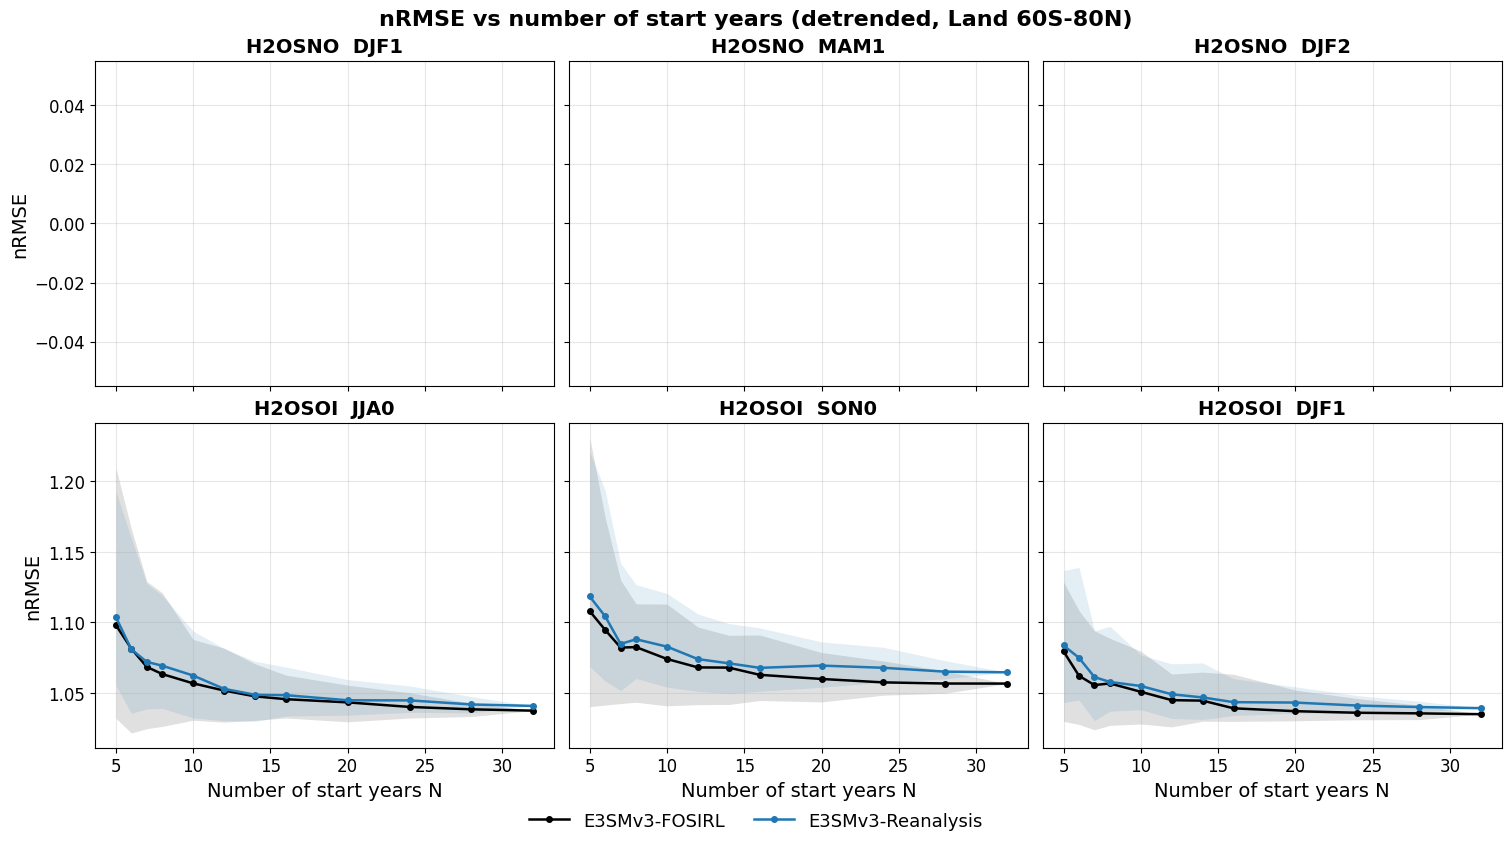

In [9]:
rows = []
for group, fields in DATA.items():
    for field, experiments in fields.items():
        for key, d in experiments.items():
            fmean = d["members"].mean("M")
            n_max = fmean.sizes["Y"]
            for n in sorted({n for n in N_GRID if n <= n_max} | {n_max}):
                weights = sss.random_subsets(n_max, n, N_DRAWS, rng)
                scores = sss.year_subset_scores(fmean, d["obs"], weights, detrend=DETREND, reduce=REDUCE[group])
                rows += ss.summarize(scores, ["acc", "nrmse"], group=group, field=field, experiment=key, n_years=n)
        print(f"done: {group} {field}")
start_years = pd.DataFrame(rows)
start_years.to_csv(TABLE_DIR / f"sample_size_start_years_init{INIT_MONTH:02d}.csv", index=False)


def acc_threshold(ax, group, field, lead, panel):
    n = np.arange(max(4, int(panel.n_years.min())), int(panel.n_years.max()) + 1)
    ax.plot(n, sss.acc_critical_value(n, SIG_LEVEL, detrend=DETREND), "k--", lw=1, label=f"ACC sig. p<{SIG_LEVEL:g}")


trend = "detrended" if DETREND else "not detrended"
for group in DATA:
    ss.plot_curves(start_years, DATA, group, "n_years", "ACC", f"ACC vs number of start years ({trend}, {PLOT_REGION[group]})",
                   FIGURE_DIR / f"fig_sample_size_years_acc_{group}.png", metric="acc", extra=acc_threshold,
                   ylim=(-0.4, 1.0), **PLOT)
    ss.plot_curves(start_years, DATA, group, "n_years", "nRMSE", f"nRMSE vs number of start years ({trend}, {PLOT_REGION[group]})",
                   FIGURE_DIR / f"fig_sample_size_years_nrmse_{group}.png", metric="nrmse", **PLOT)

## Short records vs. the full record

Lead- and region-averaged ACC median and 5–95 % width at the `SUMMARY_N` record lengths, next to the full record.

In [10]:
acc = start_years[start_years.metric == "acc"].copy()
acc["range_90"] = acc.p95 - acc.p05
keys = ["group", "field", "experiment", "region", "lead"]
full = acc.loc[acc.groupby(keys).n_years.idxmax()].set_index(keys)
tables = []
for n in SUMMARY_N:
    at_n = acc[acc.n_years == n].set_index(keys)[["median", "range_90"]].add_suffix(f"_N{n}")
    tables.append(at_n)
summary = (pd.concat([*tables, full[["median", "range_90", "n_years"]].add_suffix("_full")], axis=1)
           .groupby(["group", "field", "experiment"]).mean().round(2))
summary.to_csv(TABLE_DIR / f"sample_size_start_years_summary_init{INIT_MONTH:02d}.csv")
summary

median_N10  range_90_N10  median_N16  \
group field   experiment                                              
atm   PRECT   E3SM-FOSIRL            0.10          0.13        0.10   
              E3SM-Reanalysis        0.13          0.14        0.14   
      PSL     E3SM-FOSIRL            0.22          0.26        0.22   
              E3SM-Reanalysis        0.24          0.30        0.24   
      TREFHT  E3SM-FOSIRL            0.24          0.23        0.24   
              E3SM-Reanalysis        0.24          0.21        0.24   
      TS      E3SM-FOSIRL            0.23          0.20        0.25   
              E3SM-Reanalysis        0.25          0.19        0.25   
lnd   H2OSNO  E3SM-FOSIRL            0.02          0.18        0.02   
              E3SM-Reanalysis       -0.00          0.21        0.01   
      H2OSOI  E3SM-FOSIRL            0.07          0.11        0.07   
              E3SM-Reanalysis        0.06          0.11        0.06   
sst   AtlNino E3SM-FOSIRL            0.28          0.89        0.29   
              E3SM-Reanalysis        0.06          0.91        0.06   
      IOD     E3SM-FOSIRL            0.22          0.97        0.22   
              E3SM-Reanalysis        0.21          0.86        0.25   
      Nino3   E3SM-FOSIRL            0.62          0.66        0.59   
              E3SM-Reanalysis        0.67          0.64        0.66   
      Nino3.4 E3SM-FOSIRL            0.71          0.55        0.68   
              E3SM-Reanalysis        0.70          0.55        0.69   
      Nino4   E3SM-FOSIRL            0.69          0.67        0.66   
              E3SM-Reanalysis        0.71          0.55        0.69   
      TNA     E3SM-FOSIRL            0.35          0.87        0.36   
              E3SM-Reanalysis        0.42          0.79        0.40   

                               range_90_N16  median_full  range_90_full  \
group field   experiment                                                  
atm   PRECT   E3SM-FOSIRL              0.08         0.10            0.0   
              E3SM-Reanalysis          0.10         0.14            0.0   
      PSL     E3SM-FOSIRL              0.17         0.22            0.0   
              E3SM-Reanalysis          0.19         0.25            0.0   
      TREFHT  E3SM-FOSIRL              0.15         0.25            0.0   
              E3SM-Reanalysis          0.13         0.25            0.0   
      TS      E3SM-FOSIRL              0.14         0.24            0.0   
              E3SM-Reanalysis          0.13         0.26            0.0   
lnd   H2OSNO  E3SM-FOSIRL              0.15         0.01            0.0   
              E3SM-Reanalysis          0.14         0.00            0.0   
      H2OSOI  E3SM-FOSIRL              0.07         0.07            0.0   
              E3SM-Reanalysis          0.08         0.06            0.0   
sst   AtlNino E3SM-FOSIRL              0.62         0.28            0.0   
              E3SM-Reanalysis          0.57         0.05            0.0   
      IOD     E3SM-FOSIRL              0.64         0.22            0.0   
              E3SM-Reanalysis          0.56         0.23            0.0   
      Nino3   E3SM-FOSIRL              0.43         0.58            0.0   
              E3SM-Reanalysis          0.36         0.65            0.0   
      Nino3.4 E3SM-FOSIRL              0.42         0.66            0.0   
              E3SM-Reanalysis          0.38         0.69            0.0   
      Nino4   E3SM-FOSIRL              0.42         0.66            0.0   
              E3SM-Reanalysis          0.34         0.68            0.0   
      TNA     E3SM-FOSIRL              0.58         0.34            0.0   
              E3SM-Reanalysis          0.54         0.39            0.0   

                               n_years_full  
group field   experiment                     
atm   PRECT   E3SM-FOSIRL              36.0  
              E3SM-Reanalysis          36.0  
      PSL     E3SM-FOSIRL              32.0  
   